# Himalayan Climbing Expeditions (1905-2019)

Data analysis and insights

## 1. Loading the cleaned data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


peaks = pd.read_csv("../data/processed/peaks.csv")
agencies = pd.read_csv("../data/processed/agencies.csv")
expeditions = pd.read_csv("../data/processed/expeditions.csv",
                          parse_dates=["basecamp_date", "highpoint_date", "termination_date"])
members = pd.read_csv("../data/processed/members.csv")
print(peaks.shape, agencies.shape, expeditions.shape, members.shape)

(469, 7) (827, 2) (10364, 19) (76519, 16)


## 2. Data analysis

The cleaned data is used to answer 6 questions.

### Question 1: Which peaks are attempted the most and how often do they succeed?

In [2]:
exp_peaks = expeditions.merge(peaks[["peak_id", "peak_name", "height_metres"]], on="peak_id")
top = exp_peaks.groupby("peak_name").agg(expeditions=("expedition_id", "count"), success_rate=("success", "mean"))
top["success_rate"] = (top["success_rate"] * 100).round(1)
top.sort_values("expeditions", ascending=False).head(10)

,expeditions,success_rate
peak_name,,
Everest,2149,61.7
Ama Dablam,1366,67.9
Cho Oyu,1332,63.1
Manaslu,632,54.7
Lhotse,429,58.3
Dhaulagiri I,383,42.6
Makalu,356,43.0
Baruntse,308,39.6
Pumori,265,47.9


### Question 2: How did the number of expeditions change over the decades?

decade
1900       4
1910       3
1920      10
1930      34
1940      15
1950     168
1960     161
1970     361
1980    1187
1990    1703
2000    3213
2010    3505
dtype: int64


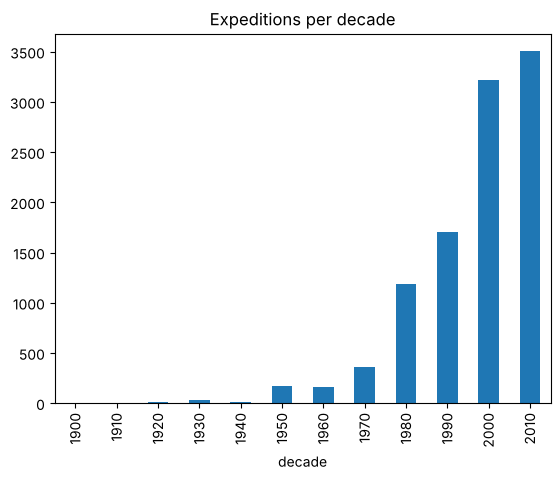

In [3]:
per_decade = expeditions.groupby("decade").size()
print(per_decade)
per_decade.plot(kind="bar")
plt.title("Expeditions per decade")
plt.show()

### Question 3: Does using oxygen help members on peaks of 8000 m and above?

In [4]:
mem = members.merge(expeditions[["expedition_id", "peak_id"]], on="expedition_id").merge(peaks[["peak_id", "height_metres"]], on="peak_id")
high = mem[mem["height_metres"] >= 8000]
print((high.groupby("oxygen_used")["success"].mean() * 100).round(1))
print((high.groupby("oxygen_used")["died"].mean() * 100).round(2))

oxygen_used
False    15.8
True     77.9
Name: success, dtype: float64
oxygen_used
False    1.91
True     1.12
Name: died, dtype: float64


### Question 4: Which season has the highest success rate?

In [5]:
season_rate = (expeditions.groupby("season")["success"].mean() * 100).round(1)
print(season_rate.sort_values(ascending=False))
print(expeditions["season"].value_counts())

season
Spring    56.9
Autumn    54.6
Winter    45.4
Summer    38.0
Name: success, dtype: float64
season
Autumn    5064
Spring    4875
Winter     315
Summer     108
Name: count, dtype: int64


### Question 5: Which peaks are the deadliest?

In [6]:
deaths = exp_peaks.groupby("peak_name").agg(members=("member_count", "sum"), deaths=("member_deaths", "sum"))
deaths = deaths[deaths["members"] >= 500]
deaths["deaths_per_1000"] = (deaths["deaths"] * 1000 / deaths["members"]).round(1)
print(deaths.sort_values("deaths_per_1000", ascending=False).head(5))
print()
print(members["death_cause"].value_counts().head(5))

               members  deaths  deaths_per_1000
peak_name                                      
Annapurna I       1453      54             37.2
Kangchenjunga     1162      34             29.3
Dhaulagiri I      2242      63             28.1
Pumori            1615      33             20.4
Manaslu           3434      69             20.1

death_cause
Avalanche                      369
Fall                           331
AMS                            102
Illness (non-AMS)               60
Disappearance (unexplained)     49
Name: count, dtype: int64


### Question 6: Who climbs in the Himalaya? (citizenship, age and women)

In [7]:
print(members["citizenship"].value_counts().head(5))
print()
print("Average age:", round(members["age"].mean(), 1))
members_year = members.merge(expeditions[["expedition_id", "decade"]], on="expedition_id")
women = members_year.groupby("decade")["sex"].apply(lambda s: (s == "F").mean() * 100).round(1)
print(women)

citizenship
Nepal     16156
USA        6526
Japan      6433
UK         5264
France     4619
Name: count, dtype: int64

Average age: 37.3
decade
1900     0.0
1910     0.0
1920     0.0
1930     1.5
1940    10.3
1950     2.6
1960     2.4
1970     4.9
1980     7.5
1990     8.8
2000     9.7
2010    11.1
Name: sex, dtype: float64
